# Model Fine-Tuning Fundamentals

Part 1 of 3 · Model Fine-Tuning, Evaluation and Deployment with AWS SageMaker

Learn when fine-tuning is the right tool, how to prepare the dataset, and why LoRA makes it affordable. This notebook runs on a laptop (no GPU, no AWS account). It also **creates the dataset files** used in Notebooks 2 and 3.

**You will learn to:**

- Choose between prompting, RAG and fine-tuning for a use case
- Compare candidate open-source models with a scorecard
- Recognise instruction, chat and completion dataset formats
- Prepare, split and validate a small training dataset
- Explain LoRA and count its trainable parameters
- Estimate GPU memory and spot common training risks

> **Before you start:** use a Python 3.10+ environment. Run the setup cell below once.

## Setup

In [1]:
%%capture
%pip install --upgrade datasets pandas matplotlib ipywidgets

In [2]:
import json, random, pathlib, collections
import pandas as pd

SEED = 42                      # fixed seed -> the same split every run
random.seed(SEED)
DATA_DIR = pathlib.Path("data")
DATA_DIR.mkdir(exist_ok=True)
print("Data folder:", DATA_DIR.resolve())

Data folder: D:\01_LMS_Course_Content\ClaudeArchitect\ClaudeArchitectProgram\Finetuning_Model\data


## 1. Fine-tuning vs prompting vs RAG

Three ways to make a model do what you need. They solve **different problems** and can be combined.

| | Prompting | RAG | Fine-tuning |
|---|---|---|---|
| What you change | The instructions and examples in the prompt | The context retrieved at request time | The model's weights |
| Best when | The behaviour can be described in words | The answer depends on private or changing knowledge | You need consistent style, format or task skill |
| Setup effort | Minutes | Days (index, retrieval) | Days to weeks (data, training, evaluation) |
| Cost pattern | Pay for long prompts on every request | Pay for retrieval plus longer prompts | One-time training, shorter prompts after |
| Updates | Edit the prompt | Re-index documents | Re-train |
| Main risk | Inconsistent output | Wrong or missing retrieval | Poor data, overfitting, forgetting |

**Rule of thumb:** try prompting first. Add RAG if the problem is *missing knowledge*. Fine-tune if the problem is *behaviour, format, or cost at scale*.

> Fine-tuning does **not** reliably teach new facts. It shapes how the model responds.

A small helper turns the rule of thumb into code, so you can test it on your own use cases.

In [3]:
def recommend(needs_private_or_changing_knowledge: bool,
              needs_consistent_format_or_style: bool,
              prompt_alone_is_good_enough: bool,
              high_volume_and_cost_sensitive: bool) -> str:
    """Return a suggested starting approach (a conversation starter, not a rule)."""
    steps = []
    if prompt_alone_is_good_enough and not high_volume_and_cost_sensitive:
        return "Prompting only"
    if needs_private_or_changing_knowledge:
        steps.append("RAG")
    if needs_consistent_format_or_style or high_volume_and_cost_sensitive:
        steps.append("Fine-tuning")
    return " + ".join(steps) if steps else "Prompting (improve the prompt first)"

cases = {
    "Answer questions from our HR policy PDFs": (True, False, False, False),
    "Classify support tickets into 10 fixed intents": (False, True, False, True),
    "Draft a friendly email from bullet points": (False, False, True, False),
    "Support bot that cites the latest product docs in a fixed tone": (True, True, False, False),
}
for name, flags in cases.items():
    print(f"{name:<65} -> {recommend(*flags)}")

Answer questions from our HR policy PDFs                          -> RAG
Classify support tickets into 10 fixed intents                    -> Fine-tuning
Draft a friendly email from bullet points                         -> Prompting only
Support bot that cites the latest product docs in a fixed tone    -> RAG + Fine-tuning


## 2. Selecting an open-source language model

Compare candidates on the same criteria, then pick the **smallest model that meets the quality bar**. The weights below are examples; set your own for your project.

| Criterion | Why it matters |
|---|---|
| Size (parameters) | Sets GPU memory, training time and serving cost |
| Base vs instruct | Instruct models already follow instructions, so they need less data |
| Licence | Some open-weight models restrict commercial use or require accepting terms |
| Context length | Must fit your longest prompt plus answer |
| Language and domain fit | A model trained mostly on English may struggle elsewhere |
| Tooling support | Is it available for fine-tuning in your platform (for example SageMaker JumpStart)? |

In [4]:
# Scores 1 (poor) to 5 (excellent). These are placeholders: replace with your own findings.
criteria_weights = {"size_fit": 0.30, "licence": 0.20, "quality_on_task": 0.30, "platform_support": 0.20}

candidates = pd.DataFrame(
    {
        "Model A (about 1B, instruct)": {"size_fit": 5, "licence": 3, "quality_on_task": 3, "platform_support": 5},
        "Model B (about 3B, instruct)": {"size_fit": 4, "licence": 5, "quality_on_task": 4, "platform_support": 4},
        "Model C (about 7B, instruct)": {"size_fit": 2, "licence": 5, "quality_on_task": 5, "platform_support": 5},
    }
).T

candidates["weighted_score"] = sum(candidates[c] * w for c, w in criteria_weights.items())
candidates.sort_values("weighted_score", ascending=False)

,size_fit,licence,quality_on_task,platform_support,weighted_score
"Model B (about 3B, instruct)",4,5,4,4,4.2
"Model C (about 7B, instruct)",2,5,5,5,4.1
"Model A (about 1B, instruct)",5,3,3,5,4.0


## 3. Understanding training datasets

A fine-tuning dataset is a list of examples that show the model **the input you will send and the output you want back**.

| Format | Looks like | Use for |
|---|---|---|
| Completion | `prompt` + `completion` text pairs | Style or domain adaptation of a base model |
| Instruction | `instruction`, optional `context`, `response` | Task skills (classify, extract, summarise) |
| Chat | A list of `system` / `user` / `assistant` messages | Conversational assistants |

Quality rules that matter more than size:

- **Consistent labels.** The same input should always get the same answer.
- **Representative inputs.** Include the messy, short and misspelt cases you will see in production.
- **No leakage.** Test examples (and near-duplicates) must never appear in training.
- **No secrets or personal data** unless you are allowed to train on them.

In [5]:
instruction_example = {
    "instruction": "Classify the intent of this message.",
    "context": "My card still has not arrived.",
    "response": "card_arrival",
}
chat_example = {
    "messages": [
        {"role": "system", "content": "You classify banking messages."},
        {"role": "user", "content": "My card still has not arrived."},
        {"role": "assistant", "content": "card_arrival"},
    ]
}
print(json.dumps(instruction_example, indent=2))
print(json.dumps(chat_example, indent=2))

{
  "instruction": "Classify the intent of this message.",
  "context": "My card still has not arrived.",
  "response": "card_arrival"
}
{
  "messages": [
    {
      "role": "system",
      "content": "You classify banking messages."
    },
    {
      "role": "user",
      "content": "My card still has not arrived."
    },
    {
      "role": "assistant",
      "content": "card_arrival"
    }
  ]
}


## 4. Dataset preparation and formatting

**Task for the lab:** classify a customer message into one of 10 banking intents. The answer is a single label, so accuracy is exact and easy to measure.

Steps: load the data, keep 10 labels, clean and de-duplicate, split by label (stratified), write JSON Lines files and a prompt template.

> The cell below downloads the public **Banking77** dataset from Hugging Face. If the download fails (no internet, blocked site), it falls back to a tiny built-in sample so the rest of the notebook still runs. **Use the real data for the lab.** Check the dataset licence before reuse.

In [6]:
LABELS = [
    "card_arrival", "lost_or_stolen_card", "exchange_rate", "card_payment_fee_charged",
    "cash_withdrawal_charge", "pin_blocked", "declined_card_payment", "top_up_failed",
    "transfer_not_received_by_recipient", "verify_my_identity",
]

FALLBACK = {
    "card_arrival": ["Where is my new card?", "My card has not come yet.", "How long until my card arrives?",
                     "I ordered a card last week and nothing arrived.", "Has my card been shipped?", "Still waiting for my card."],
    "lost_or_stolen_card": ["I lost my card.", "My card was stolen yesterday.", "I cannot find my card anywhere.",
                            "Someone took my wallet with my card.", "Please block my lost card.", "My card is missing."],
    "exchange_rate": ["What exchange rate do you use?", "How is the exchange rate decided?", "Is the rate for euros fair?",
                      "Which currency rate will I get?", "Tell me the rate for dollars.", "Why is the exchange rate different?"],
    "pin_blocked": ["My PIN is blocked.", "I entered the wrong PIN three times.", "How do I unblock my PIN?",
                    "The ATM says my PIN is locked.", "PIN blocked, help.", "I cannot use my PIN anymore."],
    "top_up_failed": ["My top up failed.", "The top-up did not go through.", "I tried to add money and it failed.",
                      "Top up error again.", "Why was my top up rejected?", "Adding funds is not working."],
}

try:
    from datasets import load_dataset
    raw = load_dataset("PolyAI/banking77")
    names = raw["train"].features["label"].names
    source = [{"text": r["text"].strip(), "label": names[r["label"]]} for r in raw["train"]]
    SOURCE_NAME = "Banking77 (Hugging Face)"
except Exception as error:
    print("Could not load Banking77, using the tiny fallback sample. Reason:", repr(error)[:120])
    source = [{"text": t, "label": l} for l, ts in FALLBACK.items() for t in ts]
    SOURCE_NAME = "built-in fallback sample (dry run only)"

available = {r["label"] for r in source}
labels = [l for l in LABELS if l in available]
rows = [r for r in source if r["label"] in labels]
print("Source:", SOURCE_NAME)
print("Labels kept:", len(labels), "| Rows:", len(rows))

README.md:   0%|          | 0.00/13.0k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  294kB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 92.4kB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/10003 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3080 [00:00<?, ? examples/s]

Source: Banking77 (Hugging Face)
Labels kept: 10 | Rows: 1399


### Clean, de-duplicate and look at the label balance

After cleaning: 1398 rows (removed 1 )


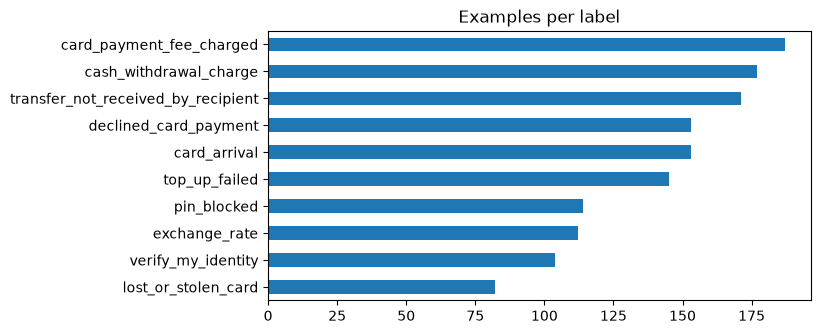

In [7]:
seen, clean = set(), []
for r in rows:
    key = r["text"].lower()
    if key in seen or len(r["text"]) < 3:
        continue
    seen.add(key)
    clean.append(r)

print("After cleaning:", len(clean), "rows (removed", len(rows) - len(clean), ")")
counts = pd.Series(collections.Counter(r["label"] for r in clean)).sort_values()
counts.plot(kind="barh", title="Examples per label", figsize=(7, 3.5));

### Training, validation and test datasets

| Split | Role | Rule |
|---|---|---|
| **Train** | The model learns from it | Largest part; capped here at 100 per label to keep the job short |
| **Validation** | Watch for overfitting while tuning | Never used to update weights |
| **Test** | One final, honest score | Touched once; the **same** file is used for base and tuned models |

Split **per label** (stratified) so every split has every label.

In [8]:
by_label = collections.defaultdict(list)
for r in clean:
    by_label[r["label"]].append(r)

train, val, test = [], [], []
for label, items in by_label.items():
    random.Random(SEED).shuffle(items)
    k = max(1, round(0.1 * len(items)))     # about 10% test, 10% validation
    k = min(k, 10)                          # at most 10 per label for test and validation
    test += items[:k]
    val += items[k:2 * k]
    train += items[2 * k:2 * k + 100]       # cap train at 100 per label

print({"train": len(train), "validation": len(val), "test": len(test)})

# Leakage check: no text may appear in two splits
t, v, s = ({r["text"].lower() for r in part} for part in (train, val, test))
assert not (t & v) and not (t & s) and not (v & s), "Leakage found between splits!"
print("No overlap between splits.")

{'train': 936, 'validation': 98, 'test': 98}
No overlap between splits.


### Format as instruction data + prompt template

JumpStart-style instruction tuning reads a JSON Lines file (`instruction`, `context`, `response`) plus a `template.json` that says how to turn each row into a **prompt** and a **completion**.

Keep the instruction text **identical in every row**, and use the **same template at inference time**. A mismatch is one of the most common reasons a tuned model looks worse than it is.

In [9]:
INSTRUCTION = "Classify the intent of this message. Choose one of: " + ", ".join(sorted(labels)) + "."

def to_example(r):
    return {"instruction": INSTRUCTION, "context": r["text"], "response": r["label"]}

template = {
    "prompt": ("Below is an instruction with an input. Write a response that completes the request.\n\n"
               "### Instruction:\n{instruction}\n\n### Input:\n{context}\n\n### Response:\n"),
    "completion": " {response}",
}

def write_jsonl(path, items):
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w") as f:
        for r in items:
            f.write(json.dumps(to_example(r)) + "\n")

write_jsonl(DATA_DIR / "train" / "train.jsonl", train)
write_jsonl(DATA_DIR / "validation" / "validation.jsonl", val)
write_jsonl(DATA_DIR / "test" / "test.jsonl", test)
json.dump(template, open(DATA_DIR / "train" / "template.json", "w"), indent=2)

for p in sorted(DATA_DIR.rglob("*")):
    if p.is_file():
        print(f"{str(p):<35} {p.stat().st_size:>8,} bytes")

data\test\test.jsonl                  37,889 bytes
data\train\template.json                 214 bytes
data\train\train.jsonl               365,134 bytes
data\validation\validation.jsonl      38,035 bytes


In [10]:
# Look at one finished training example, exactly as the model will see it
ex = to_example(train[0])
print(template["prompt"].format(**ex) + template["completion"].format(**ex))

Below is an instruction with an input. Write a response that completes the request.

### Instruction:
Classify the intent of this message. Choose one of: card_arrival, card_payment_fee_charged, cash_withdrawal_charge, declined_card_payment, exchange_rate, lost_or_stolen_card, pin_blocked, top_up_failed, transfer_not_received_by_recipient, verify_my_identity.

### Input:
Can you tell me why I haven't received my new card yet?

### Response:
 card_arrival


## 5. Parameter-efficient fine-tuning (PEFT) and LoRA

**Full fine-tuning** updates every weight, so you need memory for the weights, gradients and optimizer state, and you save a whole new copy of the model.

**PEFT** freezes the base model and trains a **small number of extra parameters**.

**LoRA (Low-Rank Adaptation)** is the most common PEFT method. For a weight matrix `W` (size `d_out x d_in`), it learns two thin matrices `A` (`r x d_in`) and `B` (`d_out x r`) and uses `W + (alpha / r) * B @ A`.

| LoRA setting | Meaning | Typical start |
|---|---|---|
| `r` (rank) | Width of the thin matrices; more = more capacity, more memory | 8 to 16 |
| `alpha` | Scale of the update | 2x to 4x `r` |
| `dropout` | Regularisation on the adapter | 0 to 0.1 |
| target modules | Which layers get adapters (often attention `q` and `v`) | q, v (or all linear layers) |

**QLoRA** also stores the frozen base weights in 4-bit, which lets larger models fit on one GPU.

### LoRA and PEFT in this lab

![Diagram comparing full fine-tuning with LoRA for the banking intent classifier. Full fine-tuning trains all 1.24 billion weights of Llama 3.2 1B. LoRA freezes them and trains two thin matrices, A and B, which add up to 0.07% of the model. The adapter turns the message "Where is my new card?" into the label card_arrival.](images/lora_peft_banking77.svg)

*Figure: full fine-tuning compared with LoRA for the banking intent task in this lab.*

**Read the figure:**

- **PEFT** (parameter-efficient fine-tuning) keeps the base model frozen and trains a small number of extra weights.
- **LoRA** is the most common PEFT method. It adds two thin matrices, `A` and `B`, next to each frozen weight matrix `W`.
- **In this lab** the adapter learns the 10 banking labels from 936 examples. The base Llama model stays unchanged.
- The numbers in the figure come from the next cell: `32,768` weights per matrix and `851,968` weights in total.

> **Note:** the figure file is `images/lora_peft_banking77.svg`, next to this notebook. Keep the `images` folder with the notebook so the figure shows.

In [11]:
def lora_params(d_out: int, d_in: int, r: int) -> int:
    """Trainable parameters LoRA adds to one weight matrix."""
    return r * (d_in + d_out)

# Illustrative shape of a ~1B model (check the real config of your model before quoting numbers)
hidden, kv_dim, layers, r = 2048, 512, 16, 8
total_model_params = 1.24e9

per_layer = lora_params(hidden, hidden, r) + lora_params(kv_dim, hidden, r)   # q_proj + v_proj
lora_total = per_layer * layers
full_attn_q = hidden * hidden

print(f"One q_proj matrix, full:  {full_attn_q:>12,} params")
print(f"One q_proj matrix, LoRA:  {lora_params(hidden, hidden, r):>12,} params ({lora_params(hidden, hidden, r) / full_attn_q:.2%})")
print(f"LoRA on q and v, all layers: {lora_total:>9,} params = {lora_total / total_model_params:.3%} of the model")

One q_proj matrix, full:     4,194,304 params
One q_proj matrix, LoRA:        32,768 params (0.78%)
LoRA on q and v, all layers:   851,968 params = 0.069% of the model


**Try changing `r`** to 16 and 64 and re-run the cell. Parameters grow linearly with `r`, but still stay a tiny fraction of the model.

## 6. Training considerations, compute requirements and limitations

**GPU memory** during training has four main parts: model weights, gradients, optimizer state, and activations (which grow with batch size and sequence length). The estimator below uses common rules of thumb and **leaves out activations**, so treat the output as a lower bound.

In [12]:
def memory_gb(params_billion: float, method: str) -> float:
    p = params_billion * 1e9
    if method == "full (mixed precision, Adam)":
        bytes_per_param = 16          # weights + gradients + Adam states + fp32 copy (rule of thumb)
    elif method == "LoRA (fp16 base)":
        bytes_per_param = 2.2         # frozen fp16 weights + small adapter states
    elif method == "QLoRA (4-bit base)":
        bytes_per_param = 0.7         # 4-bit weights + small adapter states
    else:
        raise ValueError(method)
    return p * bytes_per_param / 1e9

methods = ["full (mixed precision, Adam)", "LoRA (fp16 base)", "QLoRA (4-bit base)"]
sizes = {"1B": 1, "3B": 3, "7B": 7, "70B": 70}
table = pd.DataFrame({m: {name: round(memory_gb(b, m), 1) for name, b in sizes.items()} for m in methods})
table.index.name = "Model size"
table.style.format("{:.1f} GB")

,"full (mixed precision, Adam)",LoRA (fp16 base),QLoRA (4-bit base)
Model size,,,
1B,16.0 GB,2.2 GB,0.7 GB
3B,48.0 GB,6.6 GB,2.1 GB
7B,112.0 GB,15.4 GB,4.9 GB
70B,1120.0 GB,154.0 GB,49.0 GB


Compare the table to GPU memory (for example 24 GB on a single A10G, 80 GB on an A100/H100). A 1B model with LoRA fits easily; a 7B model with full fine-tuning does not fit on one 24 GB GPU.

### Key hyperparameters

| Hyperparameter | What it does | If it is wrong |
|---|---|---|
| Epochs | Passes over the training set | Too many: overfitting. Too few: underfitting |
| Learning rate | Step size of updates | Too high: unstable or forgetting. Too low: no change |
| Batch size / max length | Memory and speed | Too large: out-of-memory. Long inputs may be cut |
| LoRA rank / alpha | Adapter capacity and strength | Too small: cannot learn the task |

### Limitations to be honest about

- Fine-tuning shapes behaviour; it is not a database of facts.
- Small datasets can be memorised. Always keep an untouched test set.
- A tuned model can get worse at general tasks (**catastrophic forgetting**).
- Results depend on the base model, data quality and the prompt template.
- Training and hosting cost money. Delete what you do not need.

## Try it

1. Add a new use case to `cases` in section 1, predict what `recommend` returns, then check.
2. Change `r` to 32 in the LoRA cell. What share of the model is trained now?
3. Using `memory_gb`, find the largest model (in billions) that fits in 24 GB with LoRA (fp16 base).
4. Open `data/train/train.jsonl` and find two rows you would remove or fix. Why?
5. Which of your own projects needs prompting, RAG, fine-tuning, or a mix? Write one sentence for each choice.

In [13]:
# Your answers here

## Next

Open **02_SageMaker_FineTuning_Lab.ipynb**. It reads the files this notebook wrote to `data/`.